In [6]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy.optimize import minimize

@jit(nopython=True)
def P_from_nb(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def mu_from_nb(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def e_from_n(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

@jit(nopython=True)
def cs_from_n(mu,K,Gam,n_list):
    t1 = 1/mu
    t2 = K*Gam*((n_list)**(Gam-1))
    t = t1*t2
    return t

@jit(nopython=True)
def k(p_initial,n_initial,gam):
    result = p_initial/(n_initial**gam)
    return result

@jit(nopython=True)
def calculate_m0(energy_density, K, n, Gam):
    return (energy_density - (K * (n ** Gam)) / (Gam - 1)) / n

n0 = 0.16

def ntt(z):
    return np.linspace(1.4*0.16,2*0.16,z)

def delta_nt(nt,z):
    return np.linspace(0.2*nt,0.6*nt,z)

def gamm_h(z):
    return np.linspace(1.1,4,z)
def gamm_q(z):
    return np.linspace(1.1,4,z)

def seidov_limit_constraint(delta_epsilon, epsilon_c, P_c):
    lhs = delta_epsilon / epsilon_c
    rhs = 0.5 + 1.5 * (P_c / epsilon_c)
    
    # Return True if lhs is greater than or equal to rhs, else False
    return lhs >= rhs

import itertools

def constructing_EOS(n, y):

    p, mu, e, cs = [], [], [], []
    p_c_total, mu_c_total = [], []
    gam_h, gam_q =[], []
    n_transition, delta_n = [], []
    z = n // 2
    
    #gamma_h = gamm_h(z)
    #gamma_q = gamm_q(z)

    gamma_h = [4.921]  # Instead of gamm_h(z)
    gamma_q = [2.5] 
    #gamma_h = [2.50,2.75,3.0,3.25,3.50]
    nt = ntt(z)
    #print(nt)
    # Generate all combinations of gamma_h, gamma_q, nt, delta_n using itertools.product
    for g_h, g_q, n_t in itertools.product(gamma_h, gamma_q, nt):
        delta_n_11 = []
        #print("n")

        # Generate delta_n for each combination of n_t
        d_n_list = delta_nt(n_t, z)
        #d_n_list = [0.1]
        
        # Iterate over delta_n values
        for d_n in d_n_list:
            #print(d_n)
            pih = 3.542
            muih = 977.5
            eih = 1.1 * 0.16 * muih - pih
            k_had = pih / (1.1 * 0.16) ** g_h

            n_had = np.linspace(1.1 * 0.16, n_t, y)

            p_had = P_from_nb(n_had, k_had, Gam=g_h)
            m_had = calculate_m0(energy_density=eih, K=k_had, n=1.1*0.16, Gam=g_h)
            mu_had = mu_from_nb(n_list=n_had, K=k_had, Gam=g_h, m0=m_had)
            e_had = e_from_n(n_list=n_had, K=k_had, Gam=g_h, m0=m_had)
            cs_had = cs_from_n(mu=mu_had, K=k_had, Gam=g_h, n_list=n_had)

            if cs_had[-1] < 5:

                n_mid = np.linspace(n_t, n_t + d_n, y)

                p_mid = np.linspace(p_had[-1], p_had[-1], y)
                mu_mid = np.linspace(mu_had[-1], mu_had[-1], y)
                e_mid = n_mid * mu_mid - p_mid
                cs_mid = np.gradient(p_mid, e_mid)

                delta_e = e_mid[-1] - e_mid[0]
                p_c = p_had[-1]
                mu_c = mu_had[-1]
                e_c = e_had[-1]
                
                truth_value = True  # Assuming Seidov limit is always satisfied for now

                if truth_value:
                    n_iq = n_t + d_n
                    piq = p_had[-1]
                    k_quark = piq / (n_iq ** g_q)
                    m_quark = calculate_m0(energy_density=e_mid[-1], K=k_quark, n=n_iq, Gam=g_q)
                    n_fq = (1000 / k_quark) ** (1 / g_q)
                    #n_fq = 2
        
                    n_quark = np.linspace(n_t + d_n, n_fq, y)

                    p_quark = P_from_nb(n_quark, k_quark, Gam=g_q)
                    mu_quark = mu_from_nb(n_list=n_quark, K=k_quark, Gam=g_q, m0=m_quark)
                    e_quark = e_from_n(n_list=n_quark, K=k_quark, Gam=g_q, m0=m_quark)
                    cs_quark = cs_from_n(mu=mu_quark, K=k_quark, Gam=g_q, n_list=n_quark)

                    # Add this condition:
                    if cs_quark[-1] < 5:
                        p.append(np.concatenate((p_had, p_quark)))
                        mu.append(np.concatenate((mu_had, mu_quark)))
                        e.append(np.concatenate((e_had, e_quark)))
                        cs.append(np.concatenate((cs_had, cs_quark)))

                        gam_h.append(g_h)
                        gam_q.append(g_q)

                        n_transition.append(nt)
                        delta_n_11.append(d_n)

                        p_c_total.append(p_c)
                        mu_c_total.append(mu_c)
                delta_n.append(delta_n_11)
    # Default return if no valid result found
    return p, mu, e, cs, mu_c_total, p_c_total, gam_h, gam_q, n_transition, delta_n

In [7]:
p, mu, e, cs, mu_c_total, p_c_total, gam_h, gam_q, n_transition, delta_n = constructing_EOS(8,100)

In [8]:
e_total, p_total, mu_total, cs_total, P_crit, mu_crit = e, p, mu, cs, p_c_total, mu_c_total

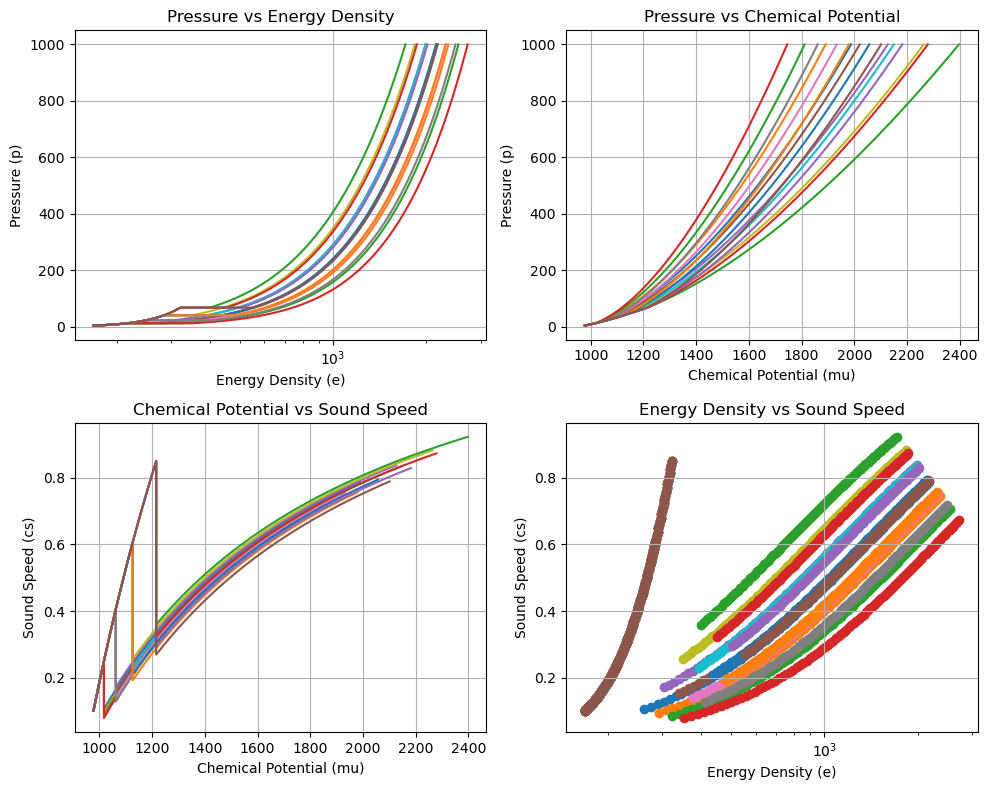

In [9]:
# Create a 2x2 grid of subplots outside the loop to include all curves in one plot
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# After the loop, plot concatenated data
for i in range(len(p)):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].plot(e_total[i], p_total[i])

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i], p_total[i])

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i], cs_total[i])

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].scatter(e_total[i], cs_total[i])

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].set_xscale('log')
#axes[0, 0].set_yscale('log')
axes[0, 0].grid(True)

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].set_xscale('log')
axes[1, 1].grid(True)

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

In [10]:
delta_P_optimal_1 = []
b_optimal_1 = []
a_optimal_1 = []
P_optimal_1 = []
min_distance_points_1 = []
min_distances_1 = []

P_all_max = []
# Iterate through each mu_total and p_total index
for index in range(len(e_total)):

    P_crit_1 = P_crit[index]*(1+0.01)
    P_crit_2 = P_crit[index]*(1+0.3)
    P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)
    delta_P = np.linspace(P_crit[index]*0.01,P_crit[index]*0.3,1000)
    
    delta_P_optimal = []
    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for i in range(len(P_crit_new)):
        P = P_crit_new[i]
        dp = delta_P[i]
        # Define your points
        x1, y1 = mu_total[index][0], p_total[index][0]  # First point the curve must pass through
        x2, y2 = mu_crit[index],P   # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[index][1:])  # Hadronic part x_values
        f_values = np.array(p_total[index][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return 0

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            delta_P_optimal.append(dp)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

        else:
            continue
    # Convert min_distances to a NumPy array
    a_optimal_1.append(a_optimal)
    b_optimal_1.append(b_optimal)
    P_optimal_1.append(P_optimal)
    delta_P_optimal_1.append(delta_P_optimal)
    min_distance_points_1.append(min_distance_points)
    min_distances_1.append(min_distances)

In [19]:
def find_first_larger_index(lst, value):
    return next((i for i, x in enumerate(lst) if x > value), None)

In [20]:
def gradient(n, m):
    
    if len(n) != len(m):
        raise ValueError("n and m must have the same length.")
    
    gradients = []
    for i in range(len(n) - 1):  # Loop up to the second-to-last element
        grad = (n[i + 1] - n[i]) / (m[i + 1] - m[i])
        gradients.append(grad)
    
    return gradients

In [21]:
import numpy as np

def concatenate_eos(min_distance_points_1,mu_crit,P_optimal_1,p_total,mu_total,a_optimal_1,b_optimal_1):
    eos_final = []
    for i in range(len(mu_crit)):

        x2, y2 = mu_crit[i], P_optimal_1[i][0]  # Critical point
        a_op = a_optimal_1[i][0]
        b_op = b_optimal_1[i][0]        
        # Define quadratic function
        def quadratic(x):
            return a_op * (x - x2)**2 + b_op * (x - x2) + y2
        
        # Generate smooth quadratic fit until quark EOS
        p_fit = quadratic(mu_total[i])
        index = find_first_larger_index(mu_total[i], min_distance_points_1[i][0][0])
        p_t = np.concatenate((p_fit[:index],p_total[i][index:]))
        eos_final.append((p_t, mu_total[i]))
        
    return eos_final

In [22]:
eos = concatenate_eos(min_distance_points_1,mu_crit,P_optimal_1,p_total,mu_total,a_optimal_1,b_optimal_1)

(0.0, 200.0)

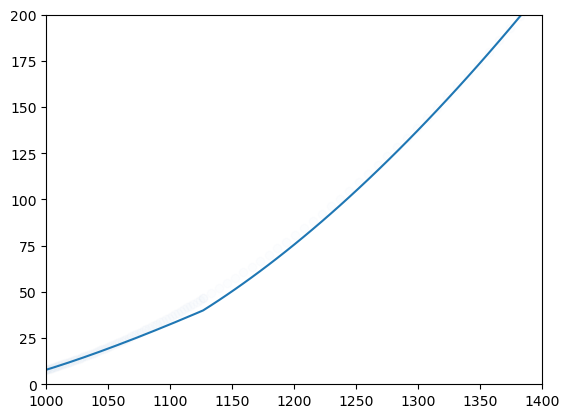

In [23]:
plt.scatter(eos[10][1],eos[10][0],alpha=0.01)
plt.plot(mu_total[10],p_total[10])
plt.xlim(1000,1400)
plt.ylim(0,200)

In [24]:
eos[1][0]

array([   3.54200001,    3.59028259,    3.63916351,    3.68864988,
          3.73874889,    3.78946783,    3.84081406,    3.89279503,
          3.94541827,    3.9986914 ,    4.05262213,    4.10721825,
          4.16248765,    4.21843829,    4.27507824,    4.33241564,
          4.39045875,    4.4492159 ,    4.50869552,    4.56890614,
          4.62985637,    4.69155495,    4.75401068,    4.81723247,
          4.88122935,    4.94601042,    5.01158491,    5.07796212,
          5.14515149,    5.21316253,    5.28200488,    5.35168827,
          5.42222256,    5.49361768,    5.56588372,    5.63903083,
          5.71306931,    5.78800954,    5.86386205,    5.94063745,
          6.0183465 ,    6.09700004,    6.17660905,    6.25718463,
          6.33873799,    6.42128047,    6.50482353,    6.58937875,
          6.67495784,    6.76157262,    6.84923507,    6.93795727,
          7.02775143,    7.1186299 ,    7.21060517,    7.30368984,
          7.39789666,    7.49323851,    7.58972841,    7.68737

In [25]:
import numpy as np

def compute_n_e(P, mu):
    """Compute number density (n_quad) and energy density (e_quad) from pressure (P) and chemical potential (mu)."""
    n_quad = gradient(P, mu)
    e_quad = (n_quad * mu[:-1]) - P[:-1]
    return n_quad, e_quad

# Lists to store results
n_quad_list = []
e_quad_list = []

# Loop through eos data
for i in range(len(eos)):
    n_quad, e_quad = compute_n_e(eos[i][0], eos[i][1])
    n_quad_list.append(n_quad)
    e_quad_list.append(e_quad)

/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_2999/4057315329.py:8: RuntimeWarning: invalid value encountered in scalar divide
  grad = (n[i + 1] - n[i]) / (m[i + 1] - m[i])


In [37]:
e_quad

array([ 171.23158255,  172.29474495,  173.38450634,  174.50133898,
        175.64572122,  176.81813761,  178.01907903,  179.24904276,
        180.50853259,  181.79805892,  183.1181389 ,  184.46929652,
        185.85206272,  187.26697553,  188.71458015,  190.19542912,
        191.71008242,  193.25910758,  194.84307987,  196.46258234,
        198.11820607,  199.81055021,  201.54022218,  203.30783778,
        205.11402137,  206.959406  ,  208.84463357,  210.77035498,
        212.73723031,  214.74592895,  216.79712981,  218.89152144,
        221.02980225,  223.21268064,  225.44087523,  227.715115  ,
        230.03613951,  232.40469904,  234.82155487,  237.28747936,
        239.80325628,  242.36968089,  244.98756024,  247.65771335,
        250.3809714 ,  253.15817799,  255.99018935,  258.87787454,
        261.82211573,  264.82380839,  267.88386156,  271.00319806,
        274.18275478,  277.42348289,  280.72634814,  284.09233106,
        287.52242728,  291.01764776,  294.5790191 ,  298.20758

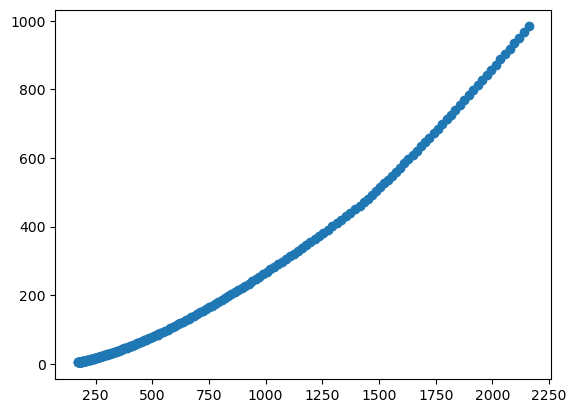

In [39]:
plt.scatter(e_quad_list[15],eos[15][0][:-1])
#plt.scatter(e_total[15],p_total[15])

In [40]:
from TOV_Solver import generate_mr_curve
from EOS_construction import constructing_EOS

In [50]:
radii, masses, compacts, love_nums = [0]*len(e_quad_list), [0]*len(e_quad_list), [0]*len(e_quad_list), [0]*len(e_quad_list)

In [51]:
for i in range(len(e_quad_list)):
    e_arr = e_quad_list[i]
    p_arr = eos[i][0]
    radii[i], masses[i], compacts[i], love_nums[i] = generate_mr_curve(e_arr, p_arr)

/Users/apple/Downloads/Thesis/Phase_Transition/code/Relation_Codes/TOV_Solver.py:49: RuntimeWarning: invalid value encountered in scalar divide
  k2 = 8 / 5 * C**5 * denom**2 * (2 + 2 * C * (y - 1) - y) / (


In [79]:
radii_1, masses_1, compacts_1, love_nums_1 = [0]*len(e_total), [0]*len(e_total), [0]*len(e_total), [0]*len(e_total)

In [80]:
for i in range(len(e_total)):
    e_arr = e_total[i]
    p_arr = p_total[i]
    radii_1[i], masses_1[i], compacts_1[i], love_nums_1[i] = generate_mr_curve(e_arr, p_arr)

In [41]:
r, m, l, c =[], [], [], []

In [42]:
r, m, l, c = generate_mr_curve(e_total[15], p_total[15])

In [43]:
r1, m1, l1, c1 =[], [], [], []
r1, m1, l1, c1 = generate_mr_curve(e_quad_list[15], p_total[15])

In [47]:
import numpy as np
cs_quad_list =[]
for i in range(len(p_total)):
    cs_quad_list.append(np.gradient(p_total[i][:-1],e_quad_list[i]))
# Initialize indices as None
i_c, i_c1 = None, None

# Iterate over the valid range
for i in range(len(e_total[0]) - 1):
    # Check if cs_total[40][i] > 1 and store the first occurrence
    if cs_total[15][i] > 1 and i_c is None:
        i_c = i
    
    # Check if cs_quad_list[i] > 1 and store the first occurrence
    elif cs_quad_list[15][i] > 1 and i_c1 is None:
        i_c1 = i

    # Exit loop early if both indices are found
    if i_c is not None and i_c1 is not None:
        break

print(f"i_c = {i_c}, i_c1 = {i_c1}")

i_c = None, i_c1 = 100


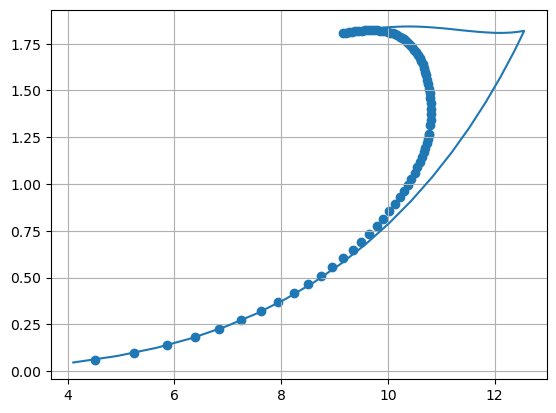

In [68]:
plt.plot(r,m)
plt.scatter(r1,m1)
plt.grid()

In [53]:
m

[0.04605913929996486,
 0.080988410280992,
 0.12439638003497255,
 0.17663817807370866,
 0.23768942904221108,
 0.30773259975903267,
 0.38677452954939906,
 0.47496639129315055,
 0.5716913213205596,
 0.6768410079710522,
 0.7897860385092699,
 0.9097515780583777,
 1.0355897554825888,
 1.1664305556015642,
 1.3008257404101733,
 1.4372084617399992,
 1.57460567504658,
 1.7113451150084864,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8180474451868653,
 1.8182965341164328,
 1.8167977354904685,
 1.8148619783240552,
 1.8128644900436701,
 1.8110415040881698,
 1.809482519322842,
 1.8085284149803411,
 1.8077797993579852,
 1.8076327423665803,
 1.8079095670262897,
 1.808800056168242,
 1.80990263

In [ ]:
def twins(mass):
    t = []
    for i in range(len(mass)-1):
        t.append(mass[i+1]-mass[i])
    #print(t)
    for j in range(len(t)-1):
        if t[j] < 0 and t[j+1]>0:
            print("Twins Exist")

In [78]:
twins(m1)

Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist
Twins Doesnot Exist


In [71]:
masses[15]

[0.08871433964590618,
 0.12804928438436375,
 0.1705690149786151,
 0.21540183027448567,
 0.26212087573933535,
 0.310112775060676,
 0.3591112861628912,
 0.4087908533725241,
 0.4590350166230529,
 0.5093171343412052,
 0.5596443934657757,
 0.61000645862769,
 0.6597914890701485,
 0.709481182078962,
 0.7585627359443718,
 0.8069036108366197,
 0.8546150296062823,
 0.9016575142980636,
 0.9480238520955362,
 0.9932936182744672,
 1.037714815512876,
 1.0813517468719327,
 1.1240581493190498,
 1.165455200926064,
 1.2061279236767268,
 1.2457262560950702,
 1.2841411631884132,
 1.3215224409567587,
 1.3580367928739734,
 1.3933513274740128,
 1.42764727848669,
 1.4608578030966237,
 1.4929202627306044,
 1.5240410795776733,
 1.5539044751028634,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0]

/Users/apple/Downloads/Thesis/Phase_Transition/code/Relation_Codes/TOV_Solver.py:49: RuntimeWarning: invalid value encountered in scalar divide
  k2 = 8 / 5 * C**5 * denom**2 * (2 + 2 * C * (y - 1) - y) / (


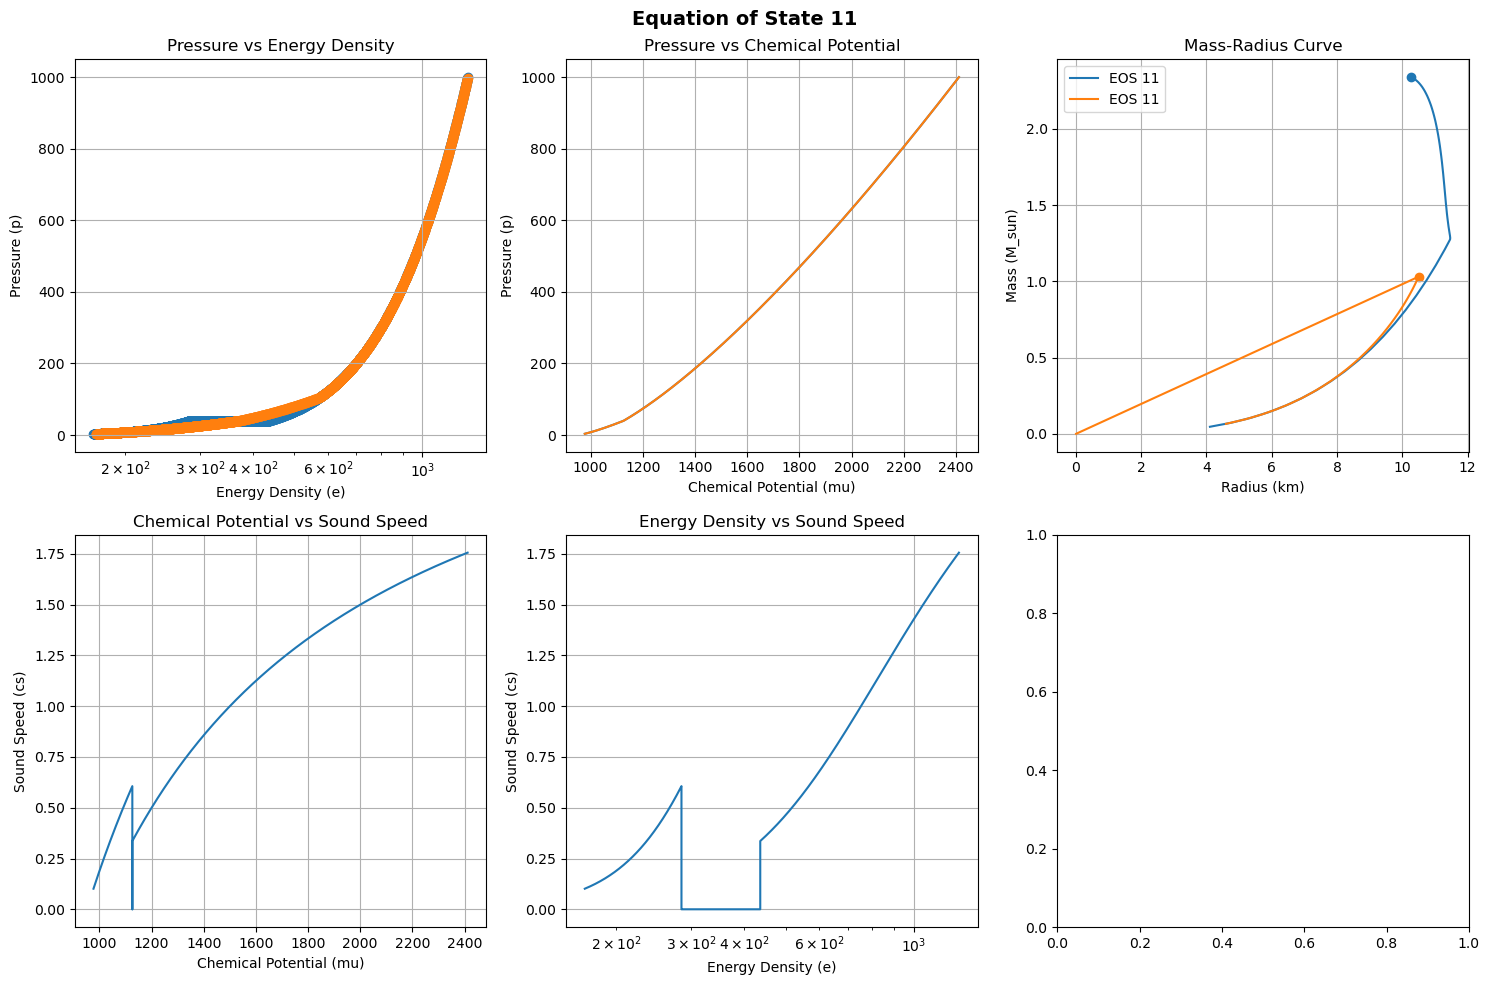

2.33931648463413
1.0303919186983135


In [74]:
import matplotlib.pyplot as plt

def plot_eos(i, e_total, p_total, mu_total, cs_total, e_quad_list):
    """
    Plots various properties of the Equation of State (EOS) for a given index.

    Parameters:
    - i: int, index of the EOS to plot
    - e_total: list of energy density values for different EOSs
    - p_total: list of pressure values for different EOSs
    - mu_total: list of chemical potential values for different EOSs
    - cs_total: list of sound speed values for different EOSs
    - generate_mr_curve: function that generates mass-radius data for an EOS
    """

    # Create a 2x3 grid of subplots
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    # Plot 1: Pressure vs Energy Density
    axes[0, 0].scatter(e_total[i], p_total[i])
    axes[0, 0].scatter(e_quad_list[i], p_total[i][:-1])
    axes[0, 0].set_title('Pressure vs Energy Density')
    axes[0, 0].set_xlabel('Energy Density (e)')
    axes[0, 0].set_ylabel('Pressure (p)')
    axes[0, 0].set_xscale('log')
    axes[0, 0].grid(True)

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i], p_total[i])
    axes[0, 1].plot(eos[i][1], p_total[i])
    axes[0, 1].set_title('Pressure vs Chemical Potential')
    axes[0, 1].set_xlabel('Chemical Potential (mu)')
    axes[0, 1].set_ylabel('Pressure (p)')
    axes[0, 1].grid(True)

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i], cs_total[i])
    axes[1, 0].set_title('Chemical Potential vs Sound Speed')
    axes[1, 0].set_ylabel('Sound Speed (cs)')
    axes[1, 0].set_xlabel('Chemical Potential (mu)')
    axes[1, 0].grid(True)

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i], cs_total[i])
    axes[1, 1].set_title('Energy Density vs Sound Speed')
    axes[1, 1].set_ylabel('Sound Speed (cs)')
    axes[1, 1].set_xlabel('Energy Density (e)')
    axes[1, 1].set_xscale('log')
    axes[1, 1].grid(True)

    # Plot 5: Mass-Radius (M-R) Curve
    radii_111, masses_111, _, _ = generate_mr_curve(e_total[i], p_total[i])
    radii_112, masses_112, _, _ = generate_mr_curve(e_quad_list[i], p_total[i])
    axes[0, 2].plot(radii_111, masses_111, label=f'EOS {i+1}')
    axes[0, 2].scatter(radii_111[np.argmax(masses_111)], masses_111[np.argmax(masses_111)])
    axes[0, 2].scatter(radii_112[np.argmax(masses_112)], masses_112[np.argmax(masses_112)])
    axes[0, 2].plot(radii_112, masses_112, label=f'EOS {i+1}')
    axes[0, 2].set_title('Mass-Radius Curve')
    axes[0, 2].set_xlabel('Radius (km)')
    axes[0, 2].set_ylabel('Mass (M_sun)')
    axes[0, 2].legend()
    axes[0, 2].grid(True)

    # Adjust layout and show the plot
    plt.suptitle(f'Equation of State {i+1}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    print(max(masses_111))
    print(max(masses_112))

plot_eos(i=10, e_total=e_total, p_total=p_total, mu_total=mu_total, cs_total=cs_total, e_quad_list=e_quad_list)